# Kde smím létat: zeměpisné zóny UAS z dat ŘLP

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/eu_rules_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kde a jak smím létat](https://openskylab.space/edu_viz_eu_rules.html) · [English version](eu_rules_en.ipynb)

Vizuál vede rozhodovacím stromem evropských pravidel pro drony. Jednu jeho větev, zeměpisné zóny UAS, tady projdeš na skutečných datech: stáhneš aktuální zóny, které zveřejňuje Řízení letového provozu ČR, zjistíš, do kterých zón padají plánovaná místa letu, jak vysoko se v okolí letišť smí létat a jak se zóny mění v čase. Je to výuková pomůcka, ne právní posouzení: před letem vždy ověř zóny v aplikaci DroneMap a podmínky v opatřeních obecné povahy ÚCL.

**Cíl:** načíst seznam zeměpisných zón a jejich soubory GeoJSON, určit zóny pro zadaná místa i pro celé území mapovacího letu, převést svislé hranice zón (AGL, AMSL, FL) na metry nad terénem, přečíst výškové omezení z gridové sítě kolem letišť a porovnat aktuální a budoucí vydání zón.

**Data:** zeměpisné zóny UAS ve formátu GeoJSON (referenční hranice) ze stránky ŘLP https://aim.rlp.cz/?lang=cz&p=uas-gz, stažené v okamžiku spuštění; nadmořská výška terénu z Digitálního modelu reliéfu ČR 5. generace (DMR 5G, ČÚZK).

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a seznam zón

In [1]:
%pip install -q shapely pyproj rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, html, json, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point, box
import shapely
from pyproj import Transformer
import rasterio

AIM = "https://aim.rlp.cz"
def get(url, tries=4, **kw):
    for i in range(tries):
        try:
            r = requests.get(url, timeout=180, **kw); r.raise_for_status(); return r
        except requests.RequestException as e:
            print(url.split("/")[-1], type(e).__name__, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError(f"Nepodařilo se stáhnout {url}")

page = get(f"{AIM}/?lang=cz&p=uas-gz").content.decode("utf-8")
rows = []
for tr in re.findall(r"<tr.*?</tr>", page, re.S):
    href = re.search(r'href="(/data/uas/[^"]+\.json)"', tr)
    cols = [re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", c))).strip() for c in re.findall(r"<td[^>]*>(.*?)</td>", tr, re.S)]
    if href and len(cols) >= 4:
        url = AIM + href.group(1)
        rows.append({"zóna": cols[0], "popis": cols[1], "soubor": cols[2], "velikost": cols[3],
                     "vydání": "aktuální" if "/actual/" in url else url.split("/")[-2], "url": url})
zones = pd.DataFrame(rows)
mb = zones.velikost.str.replace(",", ".").str.extract(r"([\d.]+)\s*(kB|MB)")
zones["MB"] = mb[0].astype(float) * np.where(mb[1] == "kB", 1e-3, 1)
pd.set_option("display.max_colwidth", 70)
zones[zones.vydání == "aktuální"][["zóna", "popis", "MB"]]

,zóna,popis,MB
0,LKR311A - Železniční zóna vnitřní - SŽ,Prostor méně než 5 m od osy krajní koleje,87.98000
1,LKR311B - Železniční zóna vnější - SŽ,Prostor od 5 do 60 m od osy krajní koleje,171.67000
2,LKR311C - Železniční zóna vnitřní - Ostatní,Prostor méně než 5 m od osy krajní koleje,1.54000
3,LKR311D - Železniční zóna vnější - Ostatní,Prostor od 5 do 60 m od osy krajní koleje,2.99000
4,LKR312A - Elektrické stanice 110kV+,Prostor ochranného pásma elektrických stanic nad 110 kV,1.11000
5,LKR312B - Elektrické vedení 220kV+,Prostor ochranného pásma elektrického vedení VVN,1.53000
6,LKR313 - Nádrže s pitnou vodou,Prostor plochy hladiny při max. vzdutí (I. ochranné pásmo),0.77510
7,LKR314A - Vnější zóna CTR a ATZ IFR,Omezený prostor od hranice CTR/ATZ IFR až po hranici vnitřní části,0.01268
8,LKR314B - Vnitřní zóna CTR a ATZ IFR,Omezený prostor <1 km od perimetru letiště a <1 km od RWZ CTL (+ 5...,0.05816
9,LKR314C - Vnější zóna CTR LKPR,Omezený prostor od hranice CTR LKPR až po hranici vnitřní části,0.00245


## 2. Do kterých zón padají místa letu?

Stáhneme zóny do zvolené velikosti souboru (největší vrstvy, např. hustě osídlený prostor nebo silnice III. třídy, mají stovky MB a v Colabu by se stahovaly dlouho). Pro každé místo zjistíme, ve kterých zónách leží a jaká je svislá hranice zóny.

In [3]:
MAX_MB = 20                   # ◀ parametr: největší stahovaný soubor (MB)
SITES = {                     # ◀ parametr: místa letu (zeměpisná šířka, délka)
    "Suchdol, kampus":        (50.130, 14.373),
    "Roztocký háj":           (50.158, 14.385),
    "Kněževes u letiště":     (50.124, 14.262),
    "Letňany":                (50.131, 14.522),
    "Pec pod Sněžkou":        (50.692, 15.733),
    "Luční bouda, Krkonoše":  (50.735, 15.697),
}
current = zones[(zones.vydání == "aktuální") & (zones.MB <= MAX_MB) & ~zones.soubor.str.startswith("GRID")]
layers = {}
for _, z in current.iterrows():
    gj = get(z.url).json()
    layers[z.soubor.replace(".json", "")] = [(shape(f["geometry"]), f.get("properties") or {}) for f in gj["features"] if f.get("geometry")]
print(f"staženo {len(layers)} vrstev, {sum(len(v) for v in layers.values())} polygonů; nestaženo (velké): {', '.join(zones[(zones.vydání == 'aktuální') & (zones.MB > MAX_MB)].soubor)}")
hits = []
for site, (lat, lon) in SITES.items():
    pt = Point(lon, lat)
    for code, feats in layers.items():
        for geom, prop in feats:
            if geom.contains(pt):
                hits.append({"místo": site, "vrstva": code, "zóna": prop.get("ident"), "svislé hranice": prop.get("vertical_limit"),
                             "popis": current.set_index(current.soubor.str.replace(".json", "")).loc[code, "popis"]})
hits = pd.DataFrame(hits)
hits if len(hits) else print("žádné místo neleží ve stažené zóně")

staženo 22 vrstev, 6904 polygonů; nestaženo (velké): LKR311A.json, LKR311B.json, LKR316.json, LKR317C.json, LKR317D.json, LKR318C.json, GRID_ATZ.json, ed_318_a1_a2_all.json


,místo,vrstva,zóna,svislé hranice,popis
0,"Suchdol, kampus",LKR314C,4LKR314C,GND - 3500 ft AMSL,Omezený prostor od hranice CTR LKPR až po hranici vnitřní části
1,"Suchdol, kampus",LKR320A,LKPR2,3500 ft AMSL - FL95,Prostory zřízené podle §44 zákona o civilním letectví a klasifikov...
2,"Suchdol, kampus",LKR320A,LKPR9,FL95 - FL165,Prostory zřízené podle §44 zákona o civilním letectví a klasifikov...
3,Roztocký háj,LKR314C,4LKR314C,GND - 3500 ft AMSL,Omezený prostor od hranice CTR LKPR až po hranici vnitřní části
4,Roztocký háj,LKR320A,LKPR2,3500 ft AMSL - FL95,Prostory zřízené podle §44 zákona o civilním letectví a klasifikov...
5,Roztocký háj,LKR320A,LKPR9,FL95 - FL165,Prostory zřízené podle §44 zákona o civilním letectví a klasifikov...
6,Kněževes u letiště,LKR314C,4LKR314C,GND - 3500 ft AMSL,Omezený prostor od hranice CTR LKPR až po hranici vnitřní části
7,Kněževes u letiště,LKR314D,5LKR314D,GND - 3500 ft AMSL,"Kružnice o poloměru 5,5 km od ARP"
8,Kněževes u letiště,LKR320A,LKPR2,3500 ft AMSL - FL95,Prostory zřízené podle §44 zákona o civilním letectví a klasifikov...
9,Kněževes u letiště,LKR320A,LKPR9,FL95 - FL165,Prostory zřízené podle §44 zákona o civilním letectví a klasifikov...


> **✏️ Úkol 1.** Ve kterých zónách leží jednotlivá místa? Které místo je bez omezení ze stažených vrstev a proč to ještě neznamená, že tam smíš létat (které velké vrstvy jsi nestáhl a co by mohly změnit)? Přidej do SITES místo, kde chceš sám létat, a výsledek porovnej s mapou DroneMap.

*Tvoje odpověď:* 

## 3. Svislé hranice zón

Zóna platí jen mezi svou dolní a horní hranicí. Hranice se udávají nad terénem (AGL), nad střední hladinou moře (AMSL) nebo jako letová hladina (FL, stovky stop při standardním tlaku 1013,25 hPa; zde ji pro jednoduchost bereme jako výšku AMSL). 1 ft = 0,3048 m. Nadmořskou výšku terénu vezmeme z digitálního modelu reliéfu DMR 5G (ČÚZK).

In [4]:
def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

FLIGHT_AGL = 120              # ◀ parametr: plánovaná výška letu nad terénem (m)
def level(txt, ground):
    """Převede jednu hranici (např. 'GND', '3500 ft AMSL', '120 m AGL', 'FL95') na metry nad terénem."""
    s = txt.strip().upper().replace(" ", "")
    if s in ("GND", "SFC"): return 0.0
    if s.startswith("FL"): return float(s[2:]) * 100 * 0.3048 - ground
    m = re.match(r"([\d.]+)(FT|M)(AGL|AMSL|MSL)", s)
    v = float(m.group(1)) * (0.3048 if m.group(2) == "FT" else 1)
    return v if m.group(3) == "AGL" else v - ground

T_JTSK = Transformer.from_crs(4326, 5514, always_xy=True)
def terrain(lat, lon):
    """Nadmořská výška terénu (m) z DMR 5G v bodě: střed malého výřezu 20 × 20 m."""
    x, y = T_JTSK.transform(lon, lat)
    z, _ = cuzk_raster("dmr5g", x - 10, y - 10, x + 10, y + 10, res=2.0)
    return float(z[z.shape[0] // 2, z.shape[1] // 2])
ground = {site: terrain(lat, lon) for site, (lat, lon) in SITES.items()}
if len(hits):
    lim = hits["svislé hranice"].str.split("-", n=1, expand=True)
    hits["terén (m n. m.)"] = hits["místo"].map(ground)
    hits["dolní (m AGL)"] = [level(a, g) for a, g in zip(lim[0], hits["terén (m n. m.)"])]
    hits["horní (m AGL)"] = [level(b, g) for b, g in zip(lim[1], hits["terén (m n. m.)"])]
    hits[f"let v {FLIGHT_AGL} m je v zóně"] = (hits["dolní (m AGL)"] <= FLIGHT_AGL) & (FLIGHT_AGL <= hits["horní (m AGL)"])
    print(hits[["místo", "zóna", "svislé hranice", "terén (m n. m.)", "dolní (m AGL)", "horní (m AGL)", f"let v {FLIGHT_AGL} m je v zóně"]].round(0).to_string())
airspace = pd.DataFrame([{"prostor": p.get("ident"), "svislé hranice": p.get("vertical_limit")} for _, p in layers.get("LKR320A", [])])
print("\nLetecké prostory LKR320A podle svislých hranic:"); print(airspace["svislé hranice"].value_counts().head(10).to_string())

                    místo        zóna               svislé hranice  terén (m n. m.)  dolní (m AGL)  horní (m AGL)  let v 120 m je v zóně
0         Suchdol, kampus    4LKR314C           GND - 3500 ft AMSL            281.0            0.0          786.0                   True
1         Suchdol, kampus       LKPR2          3500 ft AMSL - FL95            281.0          786.0         2615.0                  False
2         Suchdol, kampus       LKPR9                 FL95 - FL165            281.0         2615.0         4749.0                  False
3            Roztocký háj    4LKR314C           GND - 3500 ft AMSL            255.0            0.0          811.0                   True
4            Roztocký háj       LKPR2          3500 ft AMSL - FL95            255.0          811.0         2640.0                  False
5            Roztocký háj       LKPR9                 FL95 - FL165            255.0         2640.0         4774.0                  False
6      Kněževes u letiště    4LKR314C    

> **✏️ Úkol 2.** Vnější i vnitřní zóna CTR Praha (LKR314C a LKR314D) má horní hranici 3500 ft AMSL: kolik je to metrů nad terénem v Suchdole? Proč se některé letecké prostory LKR320A dronu ve 120 m vůbec netýkají? Proč u hranic v AMSL nebo FL záleží na výšce terénu, a co to znamená pro let na horách (Pec pod Sněžkou)?

*Tvoje odpověď:* 

## 4. Gridová síť kolem řízených letišť

V okolí řízených letišť (CTR) ŘLP zveřejňuje síť buněk 30″ × 30″ (asi 600 × 900 m), kde každá buňka udává, do jaké výšky nad terénem je let povolen bez dalšího souhlasu. Podmínky použití sítě jsou v příslušném OOP.

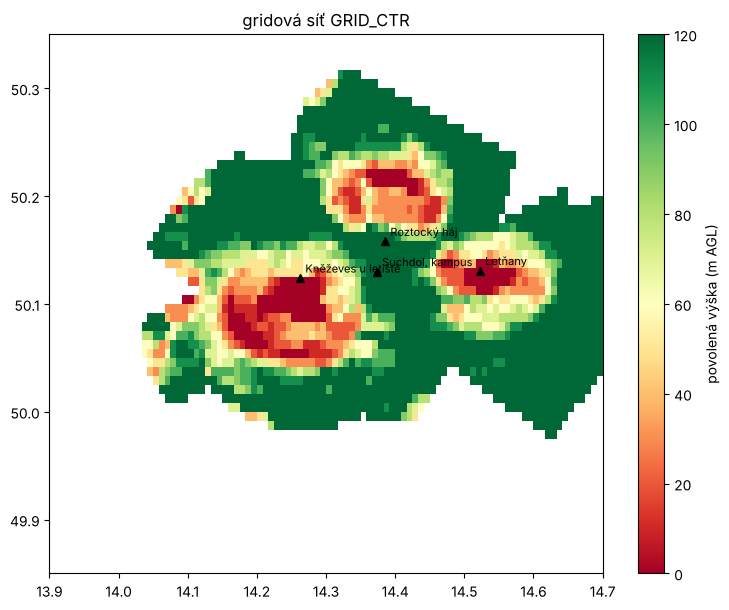

Suchdol, kampus: do 120 m nad terénem
Roztocký háj: do 120 m nad terénem
Kněževes u letiště: do 0 m nad terénem
Letňany: do 0 m nad terénem
Pec pod Sněžkou: mimo síť


Luční bouda, Krkonoše: mimo síť


In [5]:
CENTER = (50.10, 14.30)       # ◀ parametr: střed mapy (šířka, délka)
SPAN = 0.25                   # ◀ parametr: poloviční rozsah mapy (°)
grid_url = zones[(zones.vydání == "aktuální") & (zones.soubor == "GRID_CTR.json")].url.iloc[0]
grid = [(shape(f["geometry"]), f["properties"]["vertical_limit"]) for f in get(grid_url).json()["features"]]
hmax = lambda txt: float(re.search(r"-\s*([\d.]+)\s*m\s*AGL", txt).group(1))
fig, ax = plt.subplots(figsize=(9, 7))
view = box(CENTER[1] - SPAN * 1.6, CENTER[0] - SPAN, CENTER[1] + SPAN * 1.6, CENTER[0] + SPAN)
cmap = plt.get_cmap("RdYlGn")
for g, v in grid:
    if g.intersects(view):
        x, y = g.exterior.xy; ax.fill(x, y, color=cmap(hmax(v) / 120), lw=0)
for site, (lat, lon) in SITES.items():
    ax.plot(lon, lat, "k^"); ax.annotate(site, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(view.bounds[0], view.bounds[2]); ax.set_ylim(view.bounds[1], view.bounds[3]); ax.set_aspect(1 / np.cos(np.radians(CENTER[0])))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 120)); plt.colorbar(sm, ax=ax, label="povolená výška (m AGL)")
ax.set_title("gridová síť GRID_CTR"); plt.show()
for site, (lat, lon) in SITES.items():
    v = [hmax(lim) for g, lim in grid if g.contains(Point(lon, lat))]
    print(f"{site}: {'mimo síť' if not v else f'do {v[0]:.0f} m nad terénem'}")

> **✏️ Úkol 3.** Do jaké výšky smíš podle sítě létat v Suchdole a v Kněževsi? Jak se povolená výška mění směrem k přistávací dráze a proč? Posuň mapu na jiné řízené letiště (např. Brno 49,15° s. š., 16,69° v. d.) a porovnej tvar sítě. Proč je síť výhodnější než jedna velká zóna s jedinou výškou?

*Tvoje odpověď:* 

## 5. Celé území mapovacího letu

Mapovací let nepokrývá bod, ale plochu. Spočítáme, jaký podíl čtverce kolem místa leží v jednotlivých zónách (v metrech, v souřadnicích UTM 33N).

In [6]:
SITE = "Roztocký háj"         # ◀ parametr: místo ze SITES
HALF_M = 1500                 # ◀ parametr: polovina strany čtverce letu (m)
T_UTM = Transformer.from_crs(4326, 32633, always_xy=True)
to_utm = lambda g: shapely.transform(g, lambda xy: np.column_stack(T_UTM.transform(xy[:, 0], xy[:, 1])))
lat, lon = SITES[SITE]; cx, cy = T_UTM.transform(lon, lat)
area = box(cx - HALF_M, cy - HALF_M, cx + HALF_M, cy + HALF_M)
share = []
for code, feats in layers.items():
    for geom, prop in feats:
        g = to_utm(geom)
        if g.intersects(area):
            share.append({"vrstva": code, "zóna": prop.get("ident"), "svislé hranice": prop.get("vertical_limit"), "podíl území (%)": 100 * g.intersection(area).area / area.area})
for g, v in grid:
    gu = to_utm(g)
    if gu.intersects(area):
        share.append({"vrstva": "GRID_CTR", "zóna": v, "svislé hranice": v, "podíl území (%)": 100 * gu.intersection(area).area / area.area})
share = pd.DataFrame(share)
print(f"{SITE}: čtverec {2 * HALF_M / 1000:.1f} × {2 * HALF_M / 1000:.1f} km")
share.groupby(["vrstva", "svislé hranice"])["podíl území (%)"].sum().round(1).to_frame() if len(share) else print("území neleží v žádné stažené zóně")

Roztocký háj: čtverec 3.0 × 3.0 km


podíl území (%)
vrstva   svislé hranice                      
GRID_CTR GND - 100 m AGL                  3.6
         GND - 110 m AGL                  7.9
         GND - 120 m AGL                 78.9
         GND - 60 m AGL                   3.6
         GND - 80 m AGL                   2.5
         GND - 90 m AGL                   3.5
LKR312A  GND - FL660                      0.1
LKR314C   GND - 3500 ft AMSL            100.0
LKR318B  GND-FL660                       16.4
LKR320A  3500 ft AMSL - FL95            100.0
         FL95 - FL165                   100.0
         GND - 2000 ft AMSL               5.8

> **✏️ Úkol 4.** Které zóny zasahují do čtverce letu, i když samotný střed v nich neleží? Jak se výsledek změní pro čtverec 0,5 km a 3 km? Jak bys mapovací let rozdělil, aby co nejvíc plochy leželo mimo omezení, a co bys musel vyřídit pro zbytek?

*Tvoje odpověď:* 

## 6. Zóny se mění

ŘLP zveřejňuje kromě aktuálních zón i vydání, která začnou platit v budoucnu (podle cyklu AIRAC). Porovnáme vrstvy, které mají obě vydání: počet zón, jejich identifikátory a plochu, která přibude nebo ubude.

In [7]:
future = zones[(zones.vydání != "aktuální") & (zones.MB <= MAX_MB)]
if future.empty:
    print("ŘLP teď nezveřejňuje žádné budoucí vydání stažitelné velikosti.")
def load_layer(url):
    feats = [f for f in get(url).json()["features"] if f.get("geometry")]
    geoms = [shapely.make_valid(to_utm(shape(f["geometry"]))) for f in feats]
    return {f["properties"]["ident"] for f in feats}, shapely.union_all(geoms), len(feats)
for _, z in future.iterrows():
    ids0, u0, n0 = load_layer(zones[(zones.vydání == "aktuální") & (zones.soubor == z.soubor)].url.iloc[0])
    ids1, u1, n1 = load_layer(z.url)
    added, removed = sorted(ids1 - ids0), sorted(ids0 - ids1)
    print(f"{z.soubor} (vydání {z.vydání}): zón {n0} → {n1}, plocha {u0.area / 1e6:.2f} → {u1.area / 1e6:.2f} km², "
          f"přibude {u1.difference(u0).area / 1e6:.2f} km², ubude {u0.difference(u1).area / 1e6:.2f} km²")
    for name, lst in [("nové identifikátory", added), ("zrušené identifikátory", removed)]:
        if lst: print(f"   {name}: {', '.join(lst[:12])}{' …' if len(lst) > 12 else ''}")

ŘLP teď nezveřejňuje žádné budoucí vydání stažitelné velikosti.


> **✏️ Úkol 5.** Které vrstvy se v příštím vydání mění, kolik zón a plochy přibude nebo ubude? Proč musí mít dron aktuální data pro funkci geografického povědomí (geo-awareness) a proč nestačí zóny zkontrolovat jednou při plánování projektu, který trvá několik týdnů?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Spolužáci mohou mít notebook pro okolí Brna nebo Hluboké nad Vltavou. Porovnejte, jaké zóny a jaké povolené výšky ze sítě mají místa letu kolem letiště a mimo města, a čím se liší síť kolem řízeného a neřízeného letiště.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Zeměpisné zóny UAS: Řízení letového provozu České republiky, s. p., AIM, https://aim.rlp.cz/?lang=cz&p=uas-gz; mapa zón: https://dronemap.gov.cz
- Prováděcí nařízení Komise (EU) 2019/947 o pravidlech a postupech pro provoz bezpilotních letadel, čl. 15 (zeměpisné zóny UAS); nařízení v přenesené pravomoci (EU) 2019/945.
- Úřad pro civilní letectví: opatření obecné povahy k zeměpisným zónám UAS (LKR311 až LKR320), https://www.caa.gov.cz
- Výška terénu: Digitální model reliéfu ČR 5. generace (DMR 5G), © ČÚZK, licence CC BY 4.0, služba https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer

### Jak citovat

OpenSkyLab (2026). Kde smím létat: zeměpisné zóny UAS z dat ŘLP [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/eu_rules_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*